In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, accuracy_score

In [2]:
def generate_rayleigh_channel():
    h_real = np.random.randn()
    h_imag = np.random.randn()

    h = (h_real + 1j * h_imag) / np.sqrt(2)

    return h


def apply_rayleigh_fading(signal):
    h = generate_rayleigh_channel()

    faded_signal = h * signal

    return faded_signal, h

In [3]:
# Generate a QPSK test signal
n_samples = 256

i = np.random.choice([-1, 1], n_samples)
q = np.random.choice([-1, 1], n_samples)

test_signal = (i + 1j * q) / np.sqrt(2)

# Apply Rayleigh fading
faded_signal, h = apply_rayleigh_fading(test_signal)

print("Channel coefficient:", h)
print("Channel magnitude:", np.abs(h))
print("Original signal power:",
      np.mean(np.abs(test_signal)**2))
print("Faded signal power:",
      np.mean(np.abs(faded_signal)**2))

Channel coefficient: (-0.037543565437556575-0.279481929857106j)
Channel magnitude: 0.2819923197933171
Original signal power: 1.0
Faded signal power: 0.07951966842241641


In [4]:
def generate_rayleigh_dataset(
    snr_values,
    n_windows=1000,
    window_length=256
):
    X = []
    y = []
    snr_labels = []

    for snr_db in snr_values:

        # Fixed nominal noise power
        noise_power = 1 / (10 ** (snr_db / 10))

        for label in [0, 1]:

            for _ in range(n_windows):

                # Generate AWGN
                noise = np.sqrt(noise_power / 2) * (
                    np.random.randn(window_length)
                    + 1j * np.random.randn(window_length)
                )

                if label == 0:
                    # H0: Noise only
                    received_signal = noise

                else:
                    # H1: QPSK signal
                    i = np.random.choice(
                        [-1, 1], window_length
                    )
                    q = np.random.choice(
                        [-1, 1], window_length
                    )

                    signal = (i + 1j * q) / np.sqrt(2)

                    # Apply block Rayleigh fading
                    h = generate_rayleigh_channel()
                    faded_signal = h * signal

                    # Add fixed-power AWGN
                    received_signal = faded_signal + noise

                X.append(received_signal)
                y.append(label)
                snr_labels.append(snr_db)

    return (
        np.array(X),
        np.array(y),
        np.array(snr_labels)
    )

In [5]:
snr_values = np.array([-20, -15, -10, -5, 0, 5, 10])

X_rayleigh, y_rayleigh, snr_rayleigh = generate_rayleigh_dataset(
    snr_values=snr_values,
    n_windows=1000,
    window_length=256
)

print("Dataset shape:", X_rayleigh.shape)
print("Labels shape:", y_rayleigh.shape)
print("H0 samples:", np.sum(y_rayleigh == 0))
print("H1 samples:", np.sum(y_rayleigh == 1))
print("SNR values:", np.unique(snr_rayleigh))

Dataset shape: (14000, 256)
Labels shape: (14000,)
H0 samples: 7000
H1 samples: 7000
SNR values: [-20 -15 -10  -5   0   5  10]


In [6]:
np.savez_compressed(
    "rayleigh_fading_dataset.npz",
    X=X_rayleigh,
    y=y_rayleigh,
    snr=snr_rayleigh
)

print("Rayleigh fading dataset saved successfully.")

Rayleigh fading dataset saved successfully.


In [8]:
from scipy.stats import skew, kurtosis

def extract_energy_features(signal):
    energy = np.mean(np.abs(signal)**2)
    log_energy = np.log10(energy + 1e-12)
    rms = np.sqrt(energy)

    return [energy, log_energy, rms]


def extract_statistical_features(signal):
    real_part = signal.real
    imag_part = signal.imag
    magnitude = np.abs(signal)

    return [
        np.mean(real_part),
        np.mean(imag_part),
        np.std(real_part),
        np.std(imag_part),
        skew(magnitude),
        kurtosis(magnitude)
    ]


def extract_frequency_features(signal):
    spectrum = np.fft.fft(signal)
    power_spectrum = np.abs(spectrum)**2

    total_power = np.sum(power_spectrum) + 1e-12
    normalized_power = power_spectrum / total_power

    frequencies = np.fft.fftfreq(len(signal))
    abs_frequencies = np.abs(frequencies)

    centroid = np.sum(abs_frequencies * normalized_power)

    bandwidth = np.sqrt(
        np.sum(
            ((abs_frequencies - centroid)**2) * normalized_power
        )
    )

    entropy = -np.sum(
        normalized_power * np.log2(normalized_power + 1e-12)
    )

    peak_power = np.max(normalized_power)

    return [centroid, bandwidth, entropy, peak_power]

In [9]:
test_signal = X_rayleigh[0]

print("Energy features:",
      len(extract_energy_features(test_signal)))

print("Statistical features:",
      len(extract_statistical_features(test_signal)))

print("Frequency features:",
      len(extract_frequency_features(test_signal)))

Energy features: 3
Statistical features: 6
Frequency features: 4


In [10]:
X_rayleigh_features = np.array([
    extract_energy_features(x)
    + extract_statistical_features(x)
    + extract_frequency_features(x)
    for x in X_rayleigh
])

print("Feature matrix shape:", X_rayleigh_features.shape)
print("Number of features:", X_rayleigh_features.shape[1])
print("Missing values:", np.isnan(X_rayleigh_features).sum())
print("Infinite values:", np.isinf(X_rayleigh_features).sum())

Feature matrix shape: (14000, 13)
Number of features: 13
Missing values: 0
Infinite values: 0


In [11]:
np.savez_compressed(
    "rayleigh_fading_features.npz",
    X=X_rayleigh_features,
    y=y_rayleigh,
    snr=snr_rayleigh
)

print("Rayleigh fading features saved successfully.")

Rayleigh fading features saved successfully.


In [12]:
from sklearn.model_selection import train_test_split

indices = np.arange(len(y_rayleigh))

groups = np.array([
    f"{label}_{s}"
    for label, s in zip(y_rayleigh, snr_rayleigh)
])

train_idx_rayleigh, temp_idx_rayleigh = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=groups
)

temp_groups = groups[temp_idx_rayleigh]

val_idx_rayleigh, test_idx_rayleigh = train_test_split(
    temp_idx_rayleigh,
    test_size=0.50,
    random_state=42,
    stratify=temp_groups
)

print("Training samples:", len(train_idx_rayleigh))
print("Validation samples:", len(val_idx_rayleigh))
print("Testing samples:", len(test_idx_rayleigh))

Training samples: 9800
Validation samples: 2100
Testing samples: 2100


In [14]:
import joblib

scaler = joblib.load("logistic_regression_scaler.pkl")

print("Scaler loaded successfully.")
print("Number of features:", scaler.n_features_in_)

Scaler loaded successfully.
Number of features: 13


In [15]:
print("Scaler available:", "scaler" in globals())
print("LR model available:", "lr_model" in globals())
print("LR threshold available:", "lr_threshold" in globals())

Scaler available: True
LR model available: False
LR threshold available: False


In [16]:
lr_model = joblib.load("logistic_regression_model.pkl")

lr_threshold = float(
    np.load("logistic_regression_threshold.npy")
)

print("LR model and threshold restored.")
print("Threshold:", lr_threshold)

LR model and threshold restored.
Threshold: 0.7525429211626531


In [17]:
from sklearn.metrics import accuracy_score, confusion_matrix

# Extract Rayleigh test features
X_test_rayleigh = X_rayleigh_features[test_idx_rayleigh]
y_test_rayleigh = y_rayleigh[test_idx_rayleigh]

# Scale using original AWGN-trained scaler
X_test_rayleigh_scaled = scaler.transform(X_test_rayleigh)

# Predict using original Logistic Regression model
lr_rayleigh_prob = lr_model.predict_proba(
    X_test_rayleigh_scaled
)[:, 1]

# Apply original threshold
lr_rayleigh_pred = (
    lr_rayleigh_prob > lr_threshold
).astype(int)

# Calculate metrics
tn, fp, fn, tp = confusion_matrix(
    y_test_rayleigh,
    lr_rayleigh_pred,
    labels=[0, 1]
).ravel()

lr_rayleigh_accuracy = accuracy_score(
    y_test_rayleigh,
    lr_rayleigh_pred
)

lr_rayleigh_pd = tp / (tp + fn)
lr_rayleigh_pfa = fp / (fp + tn)
lr_rayleigh_pm = fn / (fn + tp)

print("LOGISTIC REGRESSION - RAYLEIGH RESULTS")
print("--------------------------------------")
print(f"Accuracy: {lr_rayleigh_accuracy:.4f}")
print(f"Pd:       {lr_rayleigh_pd:.4f}")
print(f"Pfa:      {lr_rayleigh_pfa:.4f}")
print(f"Pm:       {lr_rayleigh_pm:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_rayleigh,
    lr_rayleigh_pred
))

LOGISTIC REGRESSION - RAYLEIGH RESULTS
--------------------------------------
Accuracy: 0.6281
Pd:       0.2990
Pfa:      0.0429
Pm:       0.7010

Confusion Matrix:
[[1005   45]
 [ 736  314]]


In [18]:
import joblib
import numpy as np

rf_model = joblib.load("random_forest_model.pkl")

rf_threshold = float(
    np.load("random_forest_threshold.npy")
)

print("Random Forest loaded.")
print("Threshold:", rf_threshold)
print("Features:", rf_model.n_features_in_)

Random Forest loaded.
Threshold: 0.62
Features: 13


In [19]:
from sklearn.metrics import accuracy_score, confusion_matrix

# Rayleigh test features
X_test_rayleigh = X_rayleigh_features[test_idx_rayleigh]
y_test_rayleigh = y_rayleigh[test_idx_rayleigh]

# Predict probabilities
rf_rayleigh_prob = rf_model.predict_proba(
    X_test_rayleigh
)[:, 1]

# Apply original threshold
rf_rayleigh_pred = (
    rf_rayleigh_prob > rf_threshold
).astype(int)

# Calculate metrics
tn, fp, fn, tp = confusion_matrix(
    y_test_rayleigh,
    rf_rayleigh_pred,
    labels=[0, 1]
).ravel()

rf_rayleigh_accuracy = accuracy_score(
    y_test_rayleigh,
    rf_rayleigh_pred
)

rf_rayleigh_pd = tp / (tp + fn)
rf_rayleigh_pfa = fp / (fp + tn)
rf_rayleigh_pm = fn / (fn + tp)

print("RANDOM FOREST - RAYLEIGH RESULTS")
print("--------------------------------")
print(f"Accuracy: {rf_rayleigh_accuracy:.4f}")
print(f"Pd:       {rf_rayleigh_pd:.4f}")
print(f"Pfa:      {rf_rayleigh_pfa:.4f}")
print(f"Pm:       {rf_rayleigh_pm:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_rayleigh,
    rf_rayleigh_pred
))

RANDOM FOREST - RAYLEIGH RESULTS
--------------------------------
Accuracy: 0.6833
Pd:       0.4190
Pfa:      0.0524
Pm:       0.5810

Confusion Matrix:
[[995  55]
 [610 440]]


In [20]:
# Calculate energy for Rayleigh dataset
energy_rayleigh = np.mean(
    np.abs(X_rayleigh)**2,
    axis=1
)

# Calibrate thresholds using Rayleigh validation H0 samples
ed_rayleigh_thresholds = {}

for s in snr_values:

    mask = (
        (snr_rayleigh[val_idx_rayleigh] == s) &
        (y_rayleigh[val_idx_rayleigh] == 0)
    )

    threshold = np.quantile(
        energy_rayleigh[val_idx_rayleigh][mask],
        0.95,
        method="higher"
    )

    ed_rayleigh_thresholds[s] = threshold

print("Rayleigh Energy Detection thresholds:")

for s, threshold in ed_rayleigh_thresholds.items():
    print(f"SNR {s:>3} dB: {threshold:.6f}")

Rayleigh Energy Detection thresholds:
SNR -20 dB: 111.305292
SNR -15 dB: 34.245836
SNR -10 dB: 11.074847
SNR  -5 dB: 3.499628
SNR   0 dB: 1.089398
SNR   5 dB: 0.355155
SNR  10 dB: 0.109620


In [21]:
energy_test_rayleigh = energy_rayleigh[test_idx_rayleigh]
snr_test_rayleigh = snr_rayleigh[test_idx_rayleigh]

ed_rayleigh_pred = np.array([
    int(energy > ed_rayleigh_thresholds[s])
    for energy, s in zip(
        energy_test_rayleigh,
        snr_test_rayleigh
    )
])

tn, fp, fn, tp = confusion_matrix(
    y_test_rayleigh,
    ed_rayleigh_pred,
    labels=[0, 1]
).ravel()

ed_rayleigh_accuracy = accuracy_score(
    y_test_rayleigh,
    ed_rayleigh_pred
)

ed_rayleigh_pd = tp / (tp + fn)
ed_rayleigh_pfa = fp / (fp + tn)
ed_rayleigh_pm = fn / (fn + tp)

print("\nENERGY DETECTION - RAYLEIGH RESULTS")
print("-----------------------------------")
print(f"Accuracy: {ed_rayleigh_accuracy:.4f}")
print(f"Pd:       {ed_rayleigh_pd:.4f}")
print(f"Pfa:      {ed_rayleigh_pfa:.4f}")
print(f"Pm:       {ed_rayleigh_pm:.4f}")


ENERGY DETECTION - RAYLEIGH RESULTS
-----------------------------------
Accuracy: 0.7810
Pd:       0.6181
Pfa:      0.0562
Pm:       0.3819


In [22]:
rayleigh_comparison = pd.DataFrame([
    {
        "Model": "Energy Detection",
        "Accuracy": ed_rayleigh_accuracy,
        "Pd": ed_rayleigh_pd,
        "Pfa": ed_rayleigh_pfa,
        "Pm": ed_rayleigh_pm
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": lr_rayleigh_accuracy,
        "Pd": lr_rayleigh_pd,
        "Pfa": lr_rayleigh_pfa,
        "Pm": lr_rayleigh_pm
    },
    {
        "Model": "Random Forest",
        "Accuracy": rf_rayleigh_accuracy,
        "Pd": rf_rayleigh_pd,
        "Pfa": rf_rayleigh_pfa,
        "Pm": rf_rayleigh_pm
    }
])

print(rayleigh_comparison.round(4))

rayleigh_comparison.to_csv(
    "rayleigh_model_comparison.csv",
    index=False
)

                 Model  Accuracy      Pd     Pfa      Pm
0     Energy Detection    0.7810  0.6181  0.0562  0.3819
1  Logistic Regression    0.6281  0.2990  0.0429  0.7010
2        Random Forest    0.6833  0.4190  0.0524  0.5810


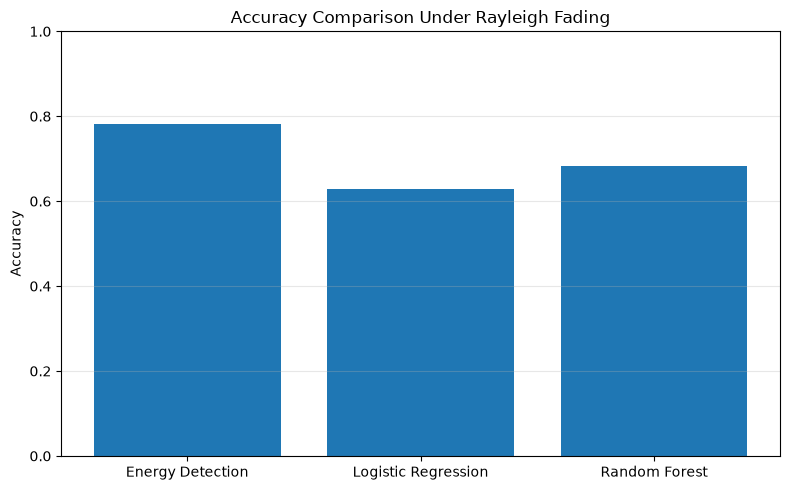

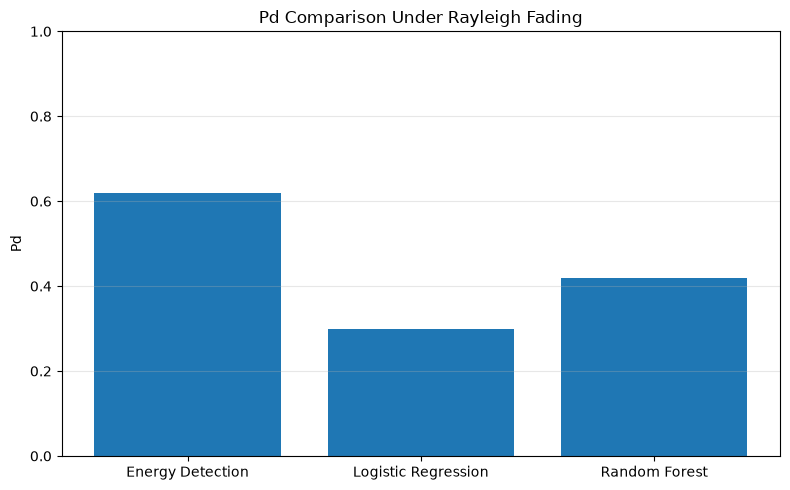

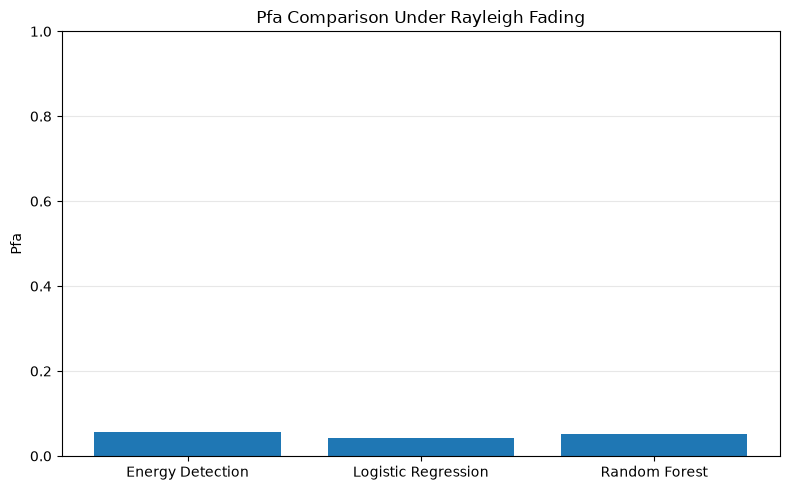

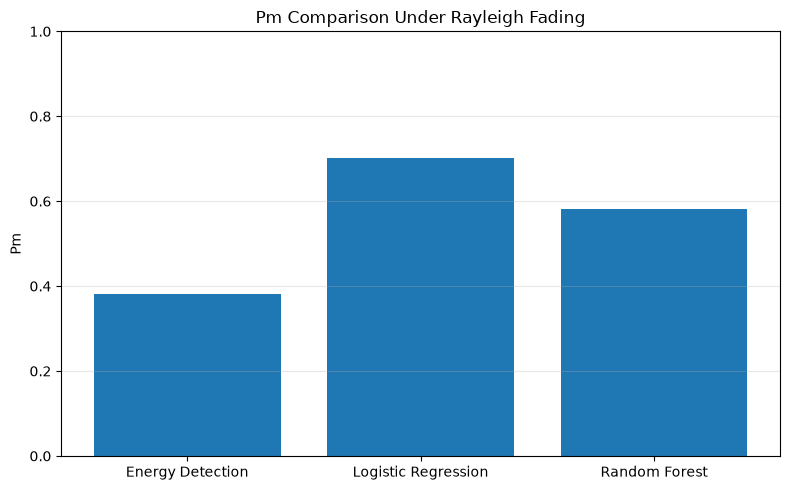

In [23]:
metrics = ["Accuracy", "Pd", "Pfa", "Pm"]

for metric in metrics:
    plt.figure(figsize=(8, 5))

    plt.bar(
        rayleigh_comparison["Model"],
        rayleigh_comparison[metric]
    )

    plt.ylabel(metric)
    plt.title(f"{metric} Comparison Under Rayleigh Fading")
    plt.ylim(0, 1)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        f"rayleigh_{metric.lower()}_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [24]:
# Extract Rayleigh validation features
X_val_rayleigh = X_rayleigh_features[val_idx_rayleigh]
y_val_rayleigh = y_rayleigh[val_idx_rayleigh]

# Apply original AWGN-trained scaler
X_val_rayleigh_scaled = scaler.transform(X_val_rayleigh)

# Predict probabilities
lr_val_rayleigh_prob = lr_model.predict_proba(
    X_val_rayleigh_scaled
)[:, 1]

# Select H0 validation probabilities
lr_h0_val_prob = lr_val_rayleigh_prob[
    y_val_rayleigh == 0
]

# Calibrate threshold for target Pfa = 0.05
target_pfa = 0.05

lr_rayleigh_threshold = np.quantile(
    lr_h0_val_prob,
    1 - target_pfa,
    method="higher"
)

print("Rayleigh-calibrated LR threshold:",
      lr_rayleigh_threshold)

print("Original AWGN threshold:",
      lr_threshold)

Rayleigh-calibrated LR threshold: 0.7502922443275002
Original AWGN threshold: 0.7525429211626531


In [25]:
lr_val_rayleigh_pred = (
    lr_val_rayleigh_prob > lr_rayleigh_threshold
).astype(int)

lr_val_rayleigh_pfa = np.mean(
    lr_val_rayleigh_pred[y_val_rayleigh == 0] == 1
)

lr_val_rayleigh_pd = np.mean(
    lr_val_rayleigh_pred[y_val_rayleigh == 1] == 1
)

print("Validation Pfa:", lr_val_rayleigh_pfa)
print("Validation Pd:", lr_val_rayleigh_pd)

Validation Pfa: 0.049523809523809526
Validation Pd: 0.30857142857142855


In [26]:
# Predict probabilities on Rayleigh validation data
rf_val_rayleigh_prob = rf_model.predict_proba(
    X_val_rayleigh
)[:, 1]

# Select H0 validation probabilities
rf_h0_val_prob = rf_val_rayleigh_prob[
    y_val_rayleigh == 0
]

# Calibrate threshold for target Pfa = 0.05
rf_rayleigh_threshold = np.quantile(
    rf_h0_val_prob,
    1 - target_pfa,
    method="higher"
)

# Apply calibrated threshold
rf_val_rayleigh_pred = (
    rf_val_rayleigh_prob > rf_rayleigh_threshold
).astype(int)

# Calculate validation metrics
rf_val_rayleigh_pfa = np.mean(
    rf_val_rayleigh_pred[y_val_rayleigh == 0] == 1
)

rf_val_rayleigh_pd = np.mean(
    rf_val_rayleigh_pred[y_val_rayleigh == 1] == 1
)

print("Rayleigh-calibrated RF threshold:",
      rf_rayleigh_threshold)

print("Validation Pfa:",
      rf_val_rayleigh_pfa)

print("Validation Pd:",
      rf_val_rayleigh_pd)

Rayleigh-calibrated RF threshold: 0.645
Validation Pfa: 0.04666666666666667
Validation Pd: 0.40190476190476193


In [28]:
lr_rayleigh_prob_test = lr_model.predict_proba(
    scaler.transform(X_test_rayleigh)
)[:, 1]

rf_rayleigh_prob_test = rf_model.predict_proba(
    X_test_rayleigh
)[:, 1]

In [29]:
# Logistic Regression with Rayleigh-calibrated threshold
lr_rayleigh_calibrated_pred = (
    lr_rayleigh_prob_test > lr_rayleigh_threshold
).astype(int)

In [30]:
from sklearn.metrics import confusion_matrix, accuracy_score

def calculate_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Pd": tp / (tp + fn),
        "Pfa": fp / (fp + tn),
        "Pm": fn / (fn + tp)
    }


# Apply Rayleigh-calibrated thresholds
lr_calibrated_pred = (
    lr_rayleigh_prob_test > lr_rayleigh_threshold
).astype(int)

rf_calibrated_pred = (
    rf_rayleigh_prob_test > rf_rayleigh_threshold
).astype(int)

# Calculate results
lr_calibrated_results = calculate_metrics(
    y_test_rayleigh, lr_calibrated_pred
)

rf_calibrated_results = calculate_metrics(
    y_test_rayleigh, rf_calibrated_pred
)

print("LOGISTIC REGRESSION")
print(pd.Series(lr_calibrated_results).round(4))

print("\nRANDOM FOREST")
print(pd.Series(rf_calibrated_results).round(4))

LOGISTIC REGRESSION
Accuracy    0.6300
Pd          0.3038
Pfa         0.0438
Pm          0.6962
dtype: float64

RANDOM FOREST
Accuracy    0.681
Pd          0.401
Pfa         0.039
Pm          0.599
dtype: float64


In [31]:
# Energy on Rayleigh validation observations
energy_val_rayleigh = energy_rayleigh[val_idx_rayleigh]

y_val_ed_pred = np.array([
    int(energy > ed_rayleigh_thresholds[s])
    for energy, s in zip(
        energy_val_rayleigh,
        snr_rayleigh[val_idx_rayleigh]
    )
])

# Validation metrics
tn, fp, fn, tp = confusion_matrix(
    y_val_rayleigh,
    y_val_ed_pred,
    labels=[0, 1]
).ravel()

ed_val_rayleigh_pd = tp / (tp + fn)
ed_val_rayleigh_pfa = fp / (fp + tn)
ed_val_rayleigh_pm = fn / (fn + tp)

print("ENERGY DETECTION - RAYLEIGH VALIDATION")
print("--------------------------------------")
print(f"Pd:  {ed_val_rayleigh_pd:.4f}")
print(f"Pfa: {ed_val_rayleigh_pfa:.4f}")
print(f"Pm:  {ed_val_rayleigh_pm:.4f}")

ENERGY DETECTION - RAYLEIGH VALIDATION
--------------------------------------
Pd:  0.5981
Pfa: 0.0467
Pm:  0.4019


In [32]:
# Energy Detection predictions on Rayleigh test set
ed_rayleigh_calibrated_pred = np.array([
    int(energy > ed_rayleigh_thresholds[s])
    for energy, s in zip(
        energy_test_rayleigh,
        snr_test_rayleigh
    )
])

# Calculate metrics
ed_calibrated_results = calculate_metrics(
    y_test_rayleigh,
    ed_rayleigh_calibrated_pred
)

# Combine all three models
rayleigh_adapted_comparison = pd.DataFrame([
    {
        "Model": "Energy Detection",
        **ed_calibrated_results
    },
    {
        "Model": "Logistic Regression",
        **lr_calibrated_results
    },
    {
        "Model": "Random Forest",
        **rf_calibrated_results
    }
])

print(rayleigh_adapted_comparison.round(4))

                 Model  Accuracy      Pd     Pfa      Pm
0     Energy Detection     0.781  0.6181  0.0562  0.3819
1  Logistic Regression     0.630  0.3038  0.0438  0.6962
2        Random Forest     0.681  0.4010  0.0390  0.5990


In [33]:
rayleigh_adapted_comparison.to_csv(
    "rayleigh_adapted_comparison.csv",
    index=False
)

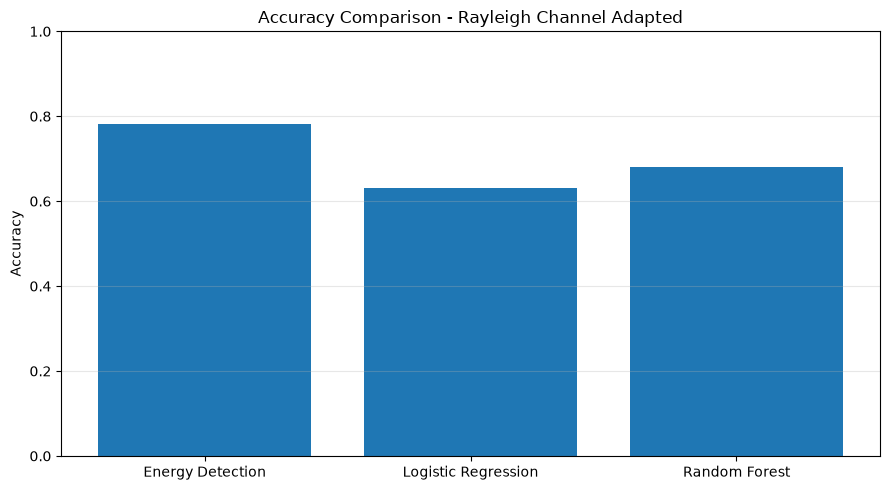

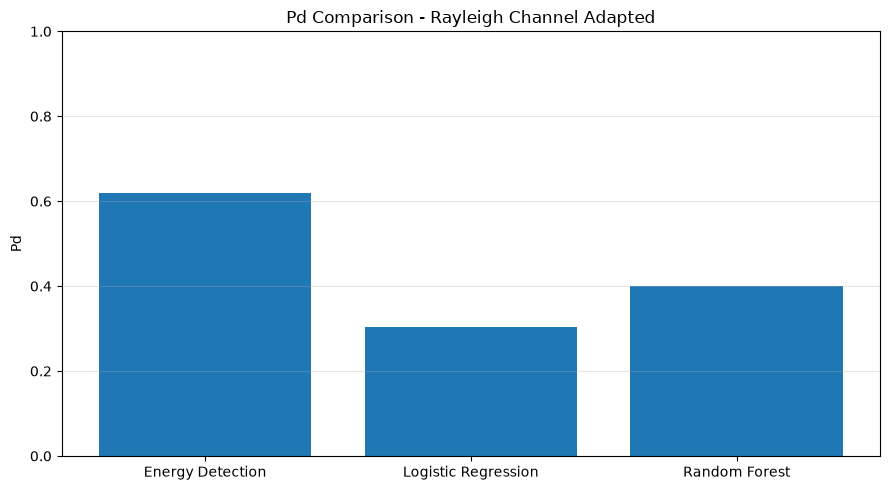

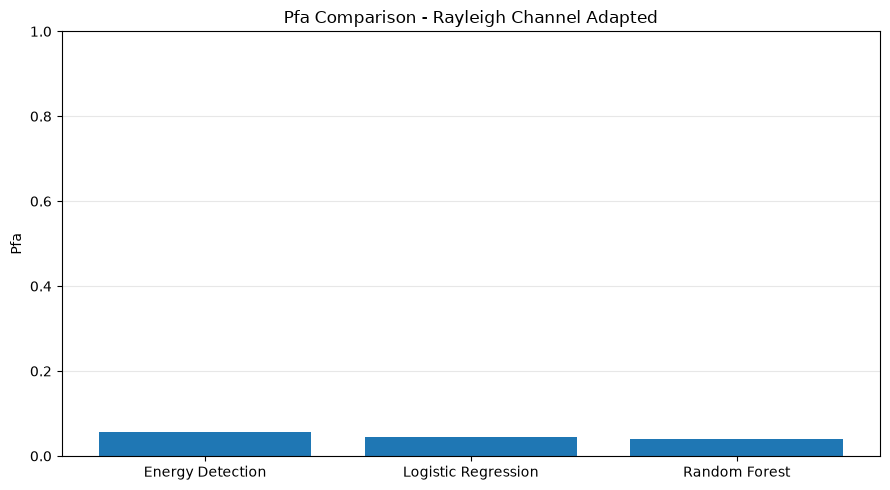

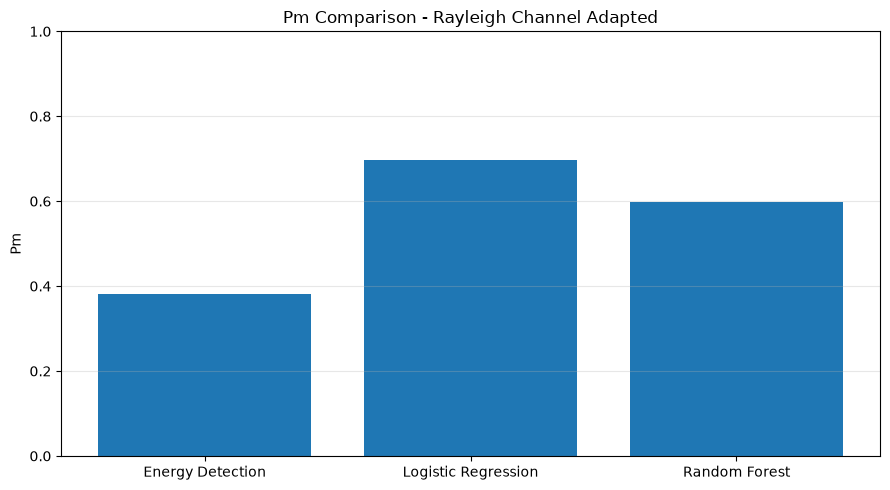

In [34]:
metrics = ["Accuracy", "Pd", "Pfa", "Pm"]

for metric in metrics:

    plt.figure(figsize=(9, 5))

    plt.bar(
        rayleigh_adapted_comparison["Model"],
        rayleigh_adapted_comparison[metric]
    )

    plt.ylabel(metric)
    plt.title(
        f"{metric} Comparison - Rayleigh Channel Adapted"
    )

    plt.ylim(0, 1)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        f"rayleigh_adapted_{metric.lower()}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()